# Respuesta en frecuencia de elementos fundamentales
**Instrumentación y Control — Universidad del Norte**

Este cuaderno acompaña la sección *Respuesta en frecuencia de elementos fundamentales* de la lectura. Para cada factor se representa el **diagrama de Bode de magnitud y fase** utilizando las ecuaciones analíticas.

Se estudian: ganancia constante, integrador, derivador ideal, polo real, cero real, tiempo muerto, polo con tiempo muerto y sistema de segundo orden. Al final se incluyen controles opcionales para explorar parámetros.

**Indicaciones:** ejecute las celdas en orden. No se requiere la biblioteca `control`; únicamente NumPy y Matplotlib para las gráficas principales.

## 0. Funciones auxiliares
Usaremos una escala logarítmica para la frecuencia $\omega$ (rad/s). La **magnitud en decibelios** y la **fase en grados** se definen como

$$M(\omega)=20\log_{10}|G(j\omega)|,\qquad \phi(\omega)=\angle G(j\omega).$$

La fase se representa *desenvuelta* cuando se acumulan más de $180^\circ$ de atraso.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Genera frecuencias positivas con separación logarítmica.
def frecuencias(wmin=0.1, wmax=100.0, n=1200):
    return np.logspace(np.log10(wmin), np.log10(wmax), n)

# Una curva se representa como (etiqueta, magnitud_dB, fase_grados, estilo).
def bode(omega, curvas, titulo, frecuencia_quiebre=None, mag_lim=None, fase_lim=None):
    fig, (ax_m, ax_f) = plt.subplots(
        2, 1, figsize=(10, 7), sharex=True,
        gridspec_kw={"height_ratios": [1, 1]}, constrained_layout=True
    )
    for etiqueta, magnitud_db, fase_grados, estilo in curvas:
        ax_m.semilogx(omega, magnitud_db, estilo, linewidth=2, label=etiqueta)
        ax_f.semilogx(omega, fase_grados, estilo, linewidth=2, label=etiqueta)

    if frecuencia_quiebre is not None:
        ax_m.axvline(frecuencia_quiebre, linestyle=":", linewidth=1.2, color="0.45")
        ax_f.axvline(frecuencia_quiebre, linestyle=":", linewidth=1.2, color="0.45")

    ax_m.set_ylabel("Magnitud (dB)")
    ax_f.set_ylabel("Fase (grados)")
    ax_f.set_xlabel(r"Frecuencia angular $\omega$ (rad/s)")
    ax_m.set_title(titulo)
    for ax in (ax_m, ax_f):
        ax.grid(True, which="both", linestyle=":", alpha=0.55)
        if len(curvas) > 1:
            ax.legend(loc="best")
    if mag_lim is not None:
        ax_m.set_ylim(*mag_lim)
    if fase_lim is not None:
        ax_f.set_ylim(*fase_lim)
    plt.show()

# Conversión de G(jw) complejo a magnitud (dB) y fase (grados).
def magnitud_y_fase(H):
    magnitud_db = 20 * np.log10(np.abs(H))
    fase_grados = np.rad2deg(np.unwrap(np.angle(H)))
    return magnitud_db, fase_grados

print("Funciones auxiliares cargadas.")

Funciones auxiliares cargadas.


## 1. Ganancia constante

Para $G(s)=K$, la magnitud no depende de la frecuencia:

$$M(\omega)=20\log_{10}|K|.$$

Si $K>0$, $\phi=0^\circ$. Si $K<0$, la fase se representa como $180^\circ$ (equivalentemente, $-180^\circ$). Compararemos tres valores para distinguir el efecto del signo.

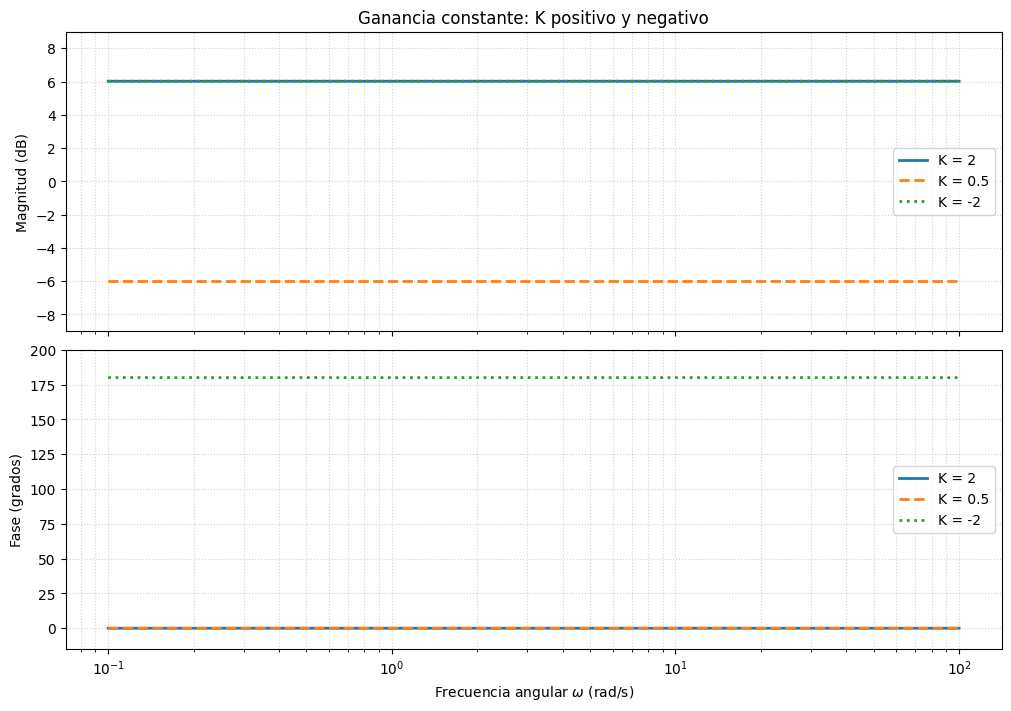

Para K = 2, la magnitud es 6.02 dB.


In [2]:
omega = frecuencias(0.1, 100)
curvas = []
for K, estilo in [(2.0, "-"), (0.5, "--"), (-2.0, ":")]:
    M = np.full_like(omega, 20*np.log10(abs(K)))
    fase = np.full_like(omega, 0.0 if K > 0 else 180.0)
    curvas.append((f"K = {K:g}", M, fase, estilo))

bode(omega, curvas, "Ganancia constante: K positivo y negativo",
     mag_lim=(-9, 9), fase_lim=(-15, 200))
print("Para K = 2, la magnitud es", round(20*np.log10(2), 2), "dB.")

## 2. Integrador

Para $G(s)=1/s$:

$$M(\omega)=-20\log_{10}\omega,\qquad \phi(\omega)=-90^\circ.$$

La magnitud disminuye **20 dB por década**. Aunque puede caracterizarse su respuesta sinusoidal, el integrador ideal **no es asintóticamente estable**; no debe confundirse su componente sinusoidal con la desaparición automática de todos los transitorios.

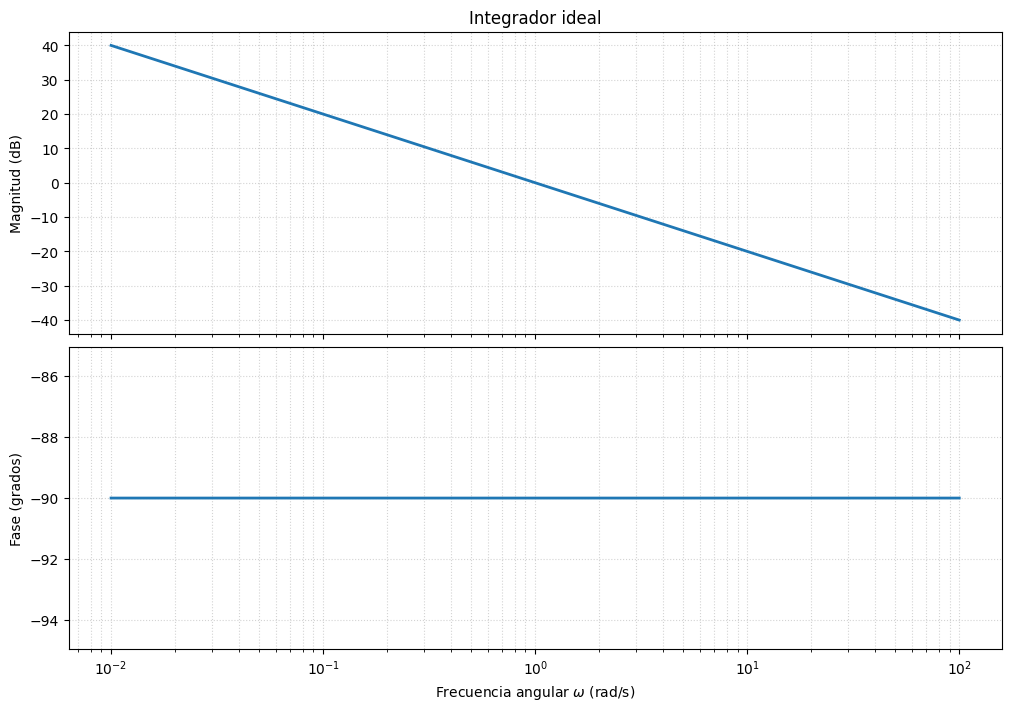

ω =  0.1 rad/s: M =  20.00 dB; fase = -90°
ω =    1 rad/s: M =  -0.00 dB; fase = -90°
ω =   10 rad/s: M = -20.00 dB; fase = -90°


In [3]:
omega = frecuencias(0.01, 100)
M = -20*np.log10(omega)
fase = np.full_like(omega, -90.0)
bode(omega, [(r"$G(s)=1/s$", M, fase, "-")], "Integrador ideal")

for w in (0.1, 1, 10):
    print(f"ω = {w:>4g} rad/s: M = {-20*np.log10(w):6.2f} dB; fase = -90°")

## 3. Derivador ideal

Para $G(s)=s$:

$$M(\omega)=20\log_{10}\omega,\qquad \phi(\omega)=+90^\circ.$$

La pendiente es **+20 dB por década**. Un derivador ideal amplifica las frecuencias altas, incluyendo el ruido, por lo que usualmente se implementa con filtrado.

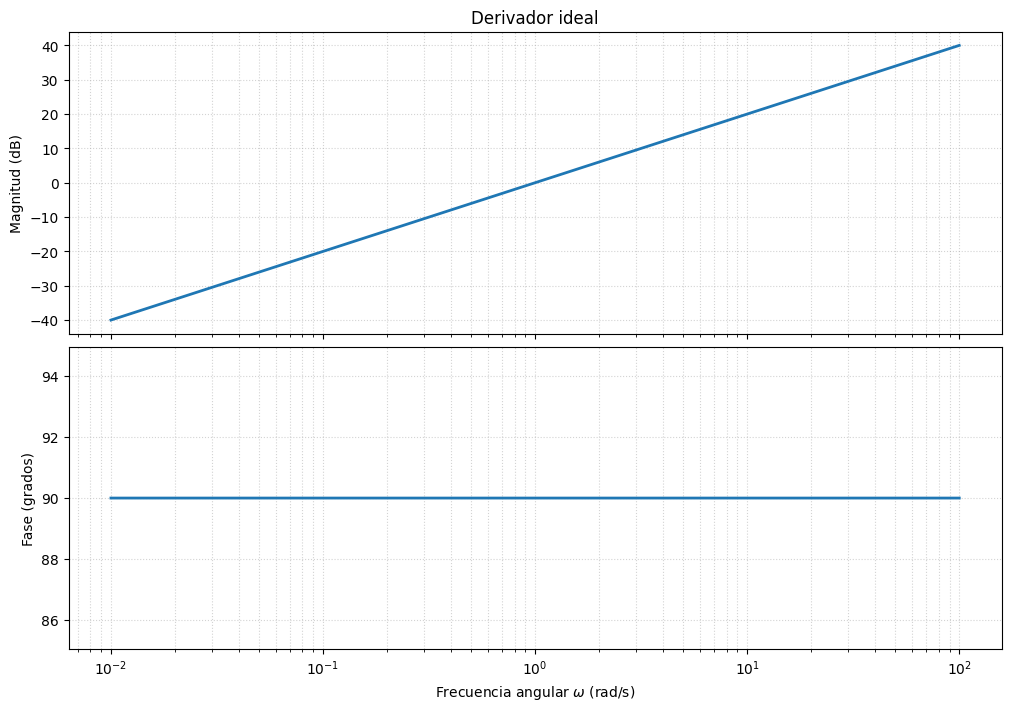

ω =  0.1 rad/s: M = -20.00 dB; fase = +90°
ω =    1 rad/s: M =   0.00 dB; fase = +90°
ω =   10 rad/s: M =  20.00 dB; fase = +90°


In [4]:
omega = frecuencias(0.01, 100)
M = 20*np.log10(omega)
fase = np.full_like(omega, 90.0)
bode(omega, [(r"$G(s)=s$", M, fase, "-")], "Derivador ideal")

for w in (0.1, 1, 10):
    print(f"ω = {w:>4g} rad/s: M = {20*np.log10(w):6.2f} dB; fase = +90°")

## 4. Polo real

Para $G(s)=1/(1+s/\omega_p)$:

$$|G(j\omega)|=\frac{1}{\sqrt{1+(\omega/\omega_p)^2}},\qquad
\phi(\omega)=-\tan^{-1}(\omega/\omega_p).$$

Usaremos $\omega_p=2$ rad/s. Se compara la magnitud **exacta** con su aproximación **asintótica**: 0 dB antes del quiebre y pendiente $-20$ dB/década después. En $\omega=\omega_p$, la respuesta exacta tiene $-3.01$ dB y $-45^\circ$.

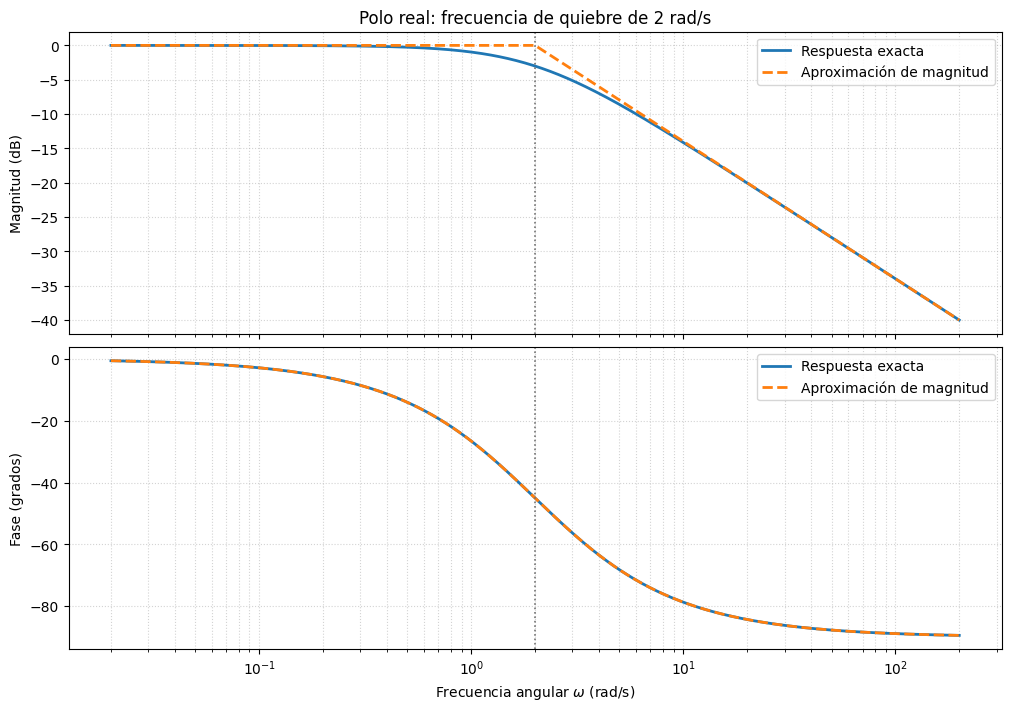

En ωp = 2 rad/s: M = -3.01 dB, fase = -45°


In [5]:
wp = 2.0  # Frecuencia de quiebre (rad/s)
omega = frecuencias(0.02, 200)
r = omega/wp
M = -10*np.log10(1+r**2)
fase = -np.degrees(np.arctan(r))
M_asint = np.where(omega < wp, 0.0, -20*np.log10(omega/wp))
# Fase asintótica: no se dibuja, para destacar la fase exacta.

bode(omega, [
    ("Respuesta exacta", M, fase, "-"),
    ("Aproximación de magnitud", M_asint, fase, "--"),
], "Polo real: frecuencia de quiebre de 2 rad/s", frecuencia_quiebre=wp)
print(f"En ωp = {wp:g} rad/s: M = {-10*np.log10(2):.2f} dB, fase = -45°")

## 5. Cero real

Para $G(s)=1+s/\omega_z$:

$$|G(j\omega)|=\sqrt{1+(\omega/\omega_z)^2},\qquad
\phi(\omega)=\tan^{-1}(\omega/\omega_z).$$

Aquí $\omega_z=5$ rad/s. La pendiente pasa de 0 a **+20 dB/década**; la fase evoluciona de 0° a +90°. En la frecuencia de quiebre, $M=+3.01$ dB y $\phi=45^\circ$.

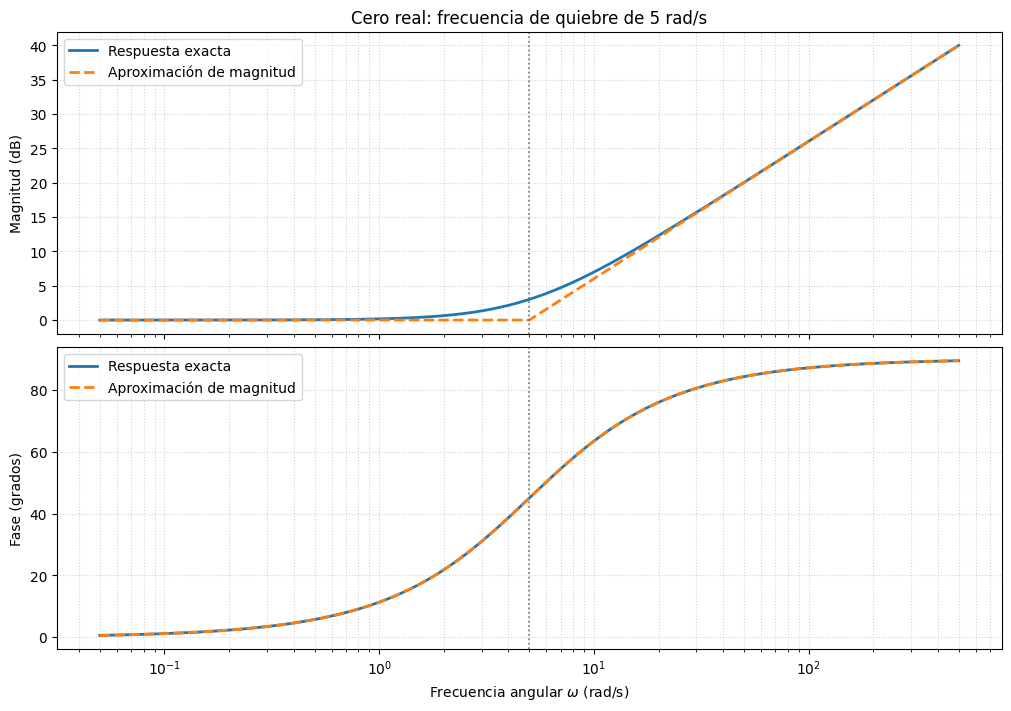

En ωz = 5 rad/s: M = 3.01 dB, fase = +45°


In [6]:
wz = 5.0
omega = frecuencias(0.05, 500)
r = omega/wz
M = 10*np.log10(1+r**2)
fase = np.degrees(np.arctan(r))
M_asint = np.where(omega < wz, 0.0, 20*np.log10(omega/wz))

bode(omega, [
    ("Respuesta exacta", M, fase, "-"),
    ("Aproximación de magnitud", M_asint, fase, "--"),
], "Cero real: frecuencia de quiebre de 5 rad/s", frecuencia_quiebre=wz)
print(f"En ωz = {wz:g} rad/s: M = {10*np.log10(2):.2f} dB, fase = +45°")

## 6. Tiempo muerto

Para un retardo puro $G(s)=e^{-Ls}$:

$$M(\omega)=0\ \mathrm{dB},\qquad
\phi(\omega)=-\omega L\,\frac{180}{\pi}\quad\mathrm{(grados)}.$$

Tomamos $L=0.5$ s. La magnitud no cambia, pero el atraso de fase aumenta sin límite a medida que aumenta la frecuencia. **No se envuelve la fase en el intervalo $[-180^\circ,180^\circ]$.**

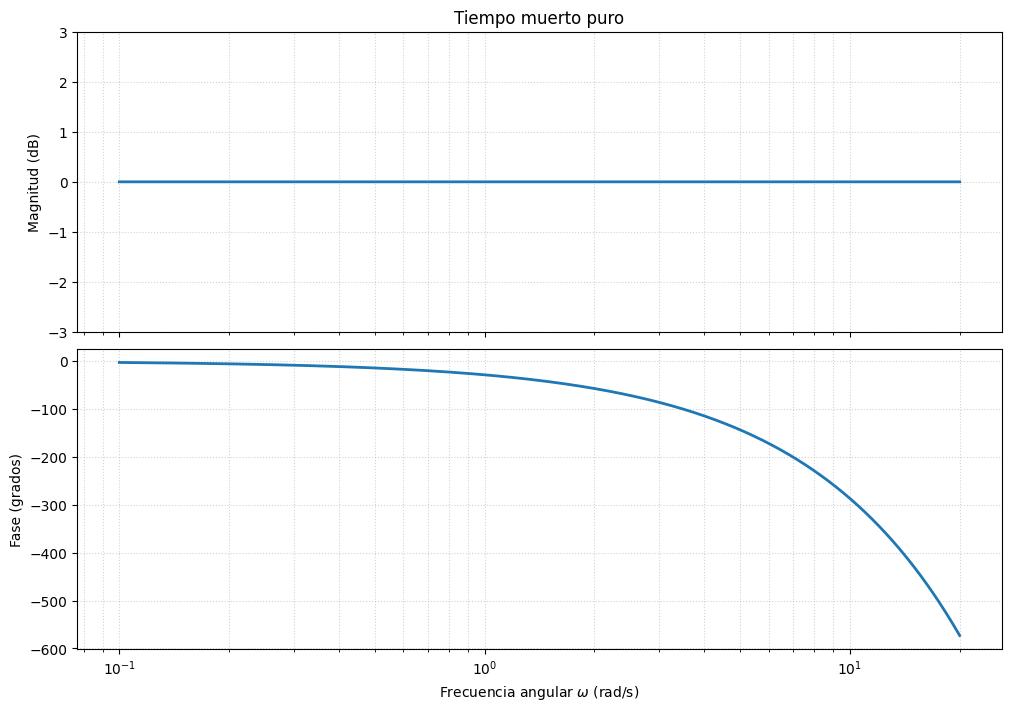

ω =  1 rad/s: fase =  -28.65°
ω =  5 rad/s: fase = -143.24°
ω = 10 rad/s: fase = -286.48°
ω = 20 rad/s: fase = -572.96°


In [7]:
L = 0.5  # segundos
omega = frecuencias(0.1, 20)
M = np.zeros_like(omega)
fase = -np.degrees(omega*L)  # Fase explícitamente desenvuelta

bode(omega, [(f"L = {L:g} s", M, fase, "-")],
     "Tiempo muerto puro", mag_lim=(-3, 3))

for w in (1, 5, 10, 20):
    print(f"ω = {w:>2g} rad/s: fase = {-np.degrees(w*L):7.2f}°")

## 7. Ejemplo: un polo real con tiempo muerto

Comparemos las plantas

$$G_0(s)=\frac{1}{s+1},\qquad G_L(s)=\frac{e^{-0.5s}}{s+1}.$$

La magnitud es **idéntica** en ambas, pero el tiempo muerto introduce un atraso de fase adicional:

$$\phi_L(\omega)=-\tan^{-1}(\omega)-0.5\omega \quad\mathrm{(radianes)}.$$

Esto puede disminuir el margen de fase **cuando la planta forma parte de un lazo de control**, aunque el margen no se calcula aquí.

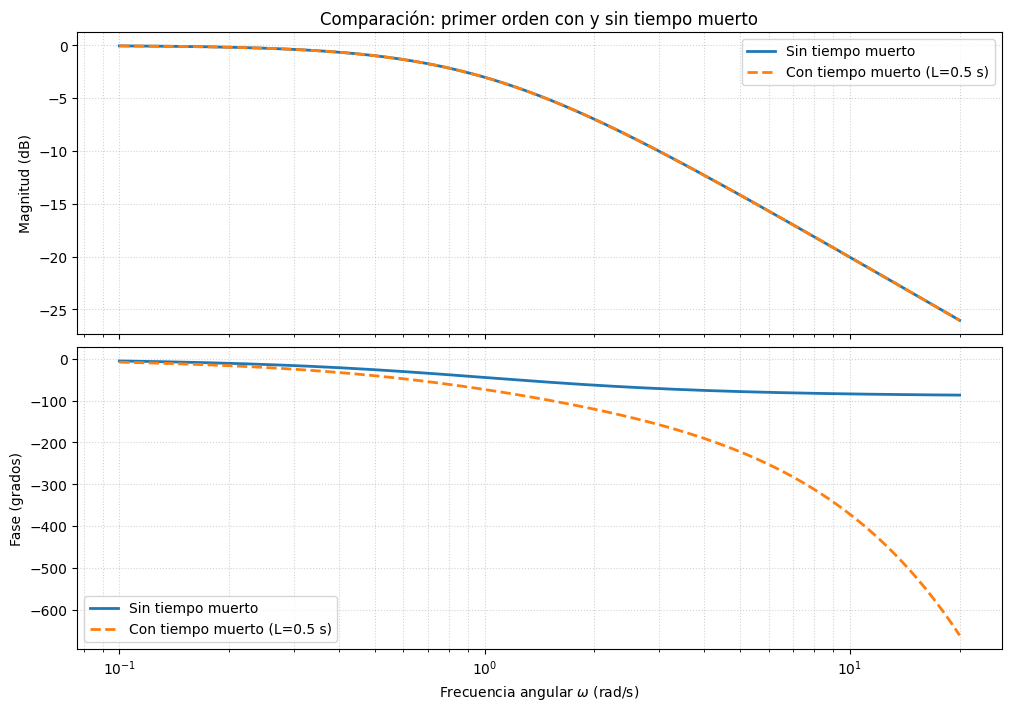

En ω = 2 rad/s, el retardo agrega -57.30° de fase.


In [8]:
omega = frecuencias(0.1, 20)
L = 0.5
magnitud = -10*np.log10(1+omega**2)
fase_sin = -np.degrees(np.arctan(omega))
fase_con = fase_sin - np.degrees(omega*L)

bode(omega, [
    ("Sin tiempo muerto", magnitud, fase_sin, "-"),
    ("Con tiempo muerto (L=0.5 s)", magnitud, fase_con, "--"),
], "Comparación: primer orden con y sin tiempo muerto")

w = 2.0
print(f"En ω = {w:g} rad/s, el retardo agrega {-np.degrees(w*L):.2f}° de fase.")

## 8. Sistema de segundo orden

Para

$$G(s)=\frac{\omega_n^2}{s^2+2\zeta\omega_n s+\omega_n^2},\qquad
r=\frac{\omega}{\omega_n},$$

$$M(\omega)=20\log_{10}\!\left(\frac{1}{\sqrt{(1-r^2)^2+(2\zeta r)^2}}\right),$$

$$\phi(\omega)=-\operatorname{atan2}(2\zeta r,1-r^2).$$

Usaremos $\omega_n=10$ rad/s y $\zeta\in\{0.1,0.3,0.707,1\}$. Para $0<\zeta<1/\sqrt2$ hay un máximo resonante:

$$\omega_r=\omega_n\sqrt{1-2\zeta^2},\qquad
M_r=\frac{1}{2\zeta\sqrt{1-\zeta^2}}.$$

**Atención:** $M_r$ es una relación lineal de amplitudes. Para expresarla en decibelios se utiliza $20\log_{10}(M_r)$.

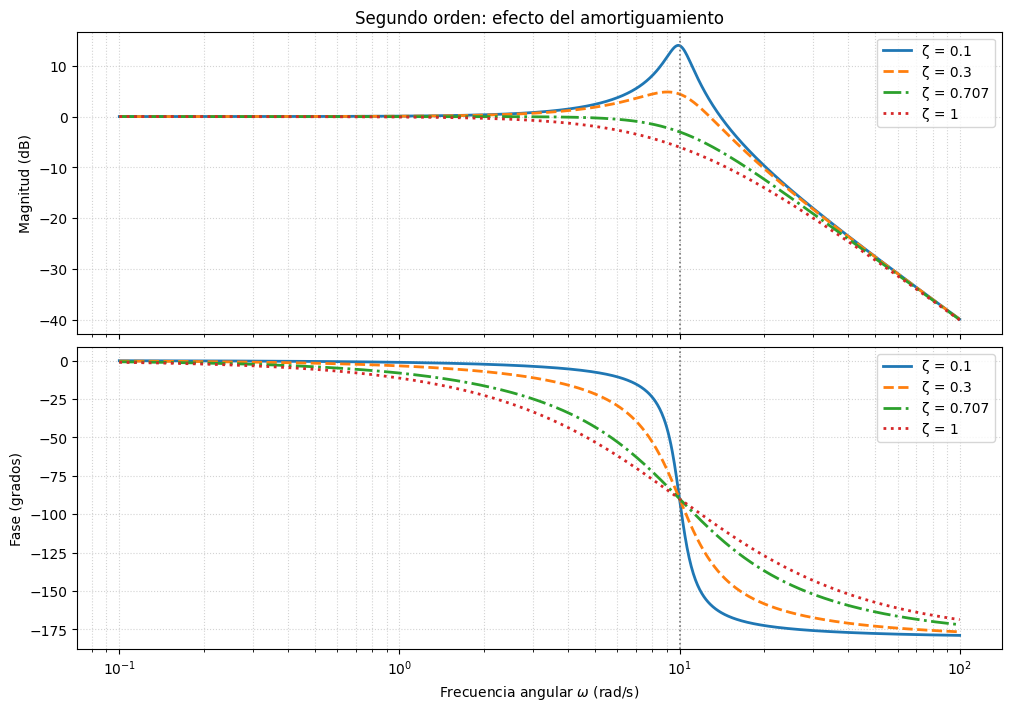

ζ = 0.1: ωr = 9.899 rad/s; Mr = 5.025; pico = 14.02 dB
ζ = 0.3: ωr = 9.055 rad/s; Mr = 1.747; pico = 4.85 dB
ζ = 0.707: no existe pico resonante interior para ω > 0.
ζ = 1: no existe pico resonante interior para ω > 0.


In [9]:
omega_n = 10.0
zeta_valores = [0.1, 0.3, 1/np.sqrt(2), 1.0]
omega = frecuencias(0.1, 100)
curvas = []

for zeta, estilo in zip(zeta_valores, ["-", "--", "-.", ":"]):
    r = omega / omega_n
    denominador = (1-r**2)**2 + (2*zeta*r)**2
    M = -10*np.log10(denominador)
    fase = -np.degrees(np.arctan2(2*zeta*r, 1-r**2))
    curvas.append((f"ζ = {zeta:.3g}", M, fase, estilo))

bode(omega, curvas, "Segundo orden: efecto del amortiguamiento",
     frecuencia_quiebre=omega_n)

for zeta in zeta_valores:
    if 0 < zeta < 1/np.sqrt(2):
        wr = omega_n*np.sqrt(1-2*zeta**2)
        Mr = 1/(2*zeta*np.sqrt(1-zeta**2))
        print(f"ζ = {zeta:.3g}: ωr = {wr:.3f} rad/s; "
              f"Mr = {Mr:.3f}; pico = {20*np.log10(Mr):.2f} dB")
    else:
        print(f"ζ = {zeta:.3g}: no existe pico resonante interior para ω > 0.")

## 9. Exploración interactiva (opcional)

Si ejecuta el cuaderno en Google Colab o Jupyter con `ipywidgets`, puede modificar la frecuencia de quiebre, el tiempo muerto y el coeficiente de amortiguamiento con deslizadores. Si `ipywidgets` no está disponible, **todas las gráficas anteriores siguen funcionando**; puede instalarlo con `%pip install ipywidgets` y ejecutar de nuevo esta celda.

En el control de segundo orden, si $\zeta$ es pequeño, observe cómo aparece un pico de resonancia cerca de $\omega_n$. En el retardo puro, observe que **solamente cambia la fase**.

In [10]:
try:
    from ipywidgets import interact, FloatSlider, FloatLogSlider, Dropdown

    @interact(
        elemento=Dropdown(options=["Polo real", "Cero real", "Tiempo muerto", "Segundo orden"]),
        frecuencia=FloatLogSlider(value=2.0, base=10, min=-1, max=2, step=0.05,
                                 description="ωp o ωz"),
        retardo=FloatSlider(value=0.5, min=0, max=2, step=0.1, description="L (s)"),
        zeta=FloatSlider(value=0.3, min=0.05, max=1.5, step=0.05, description="ζ"),
    )
    def explorar(elemento, frecuencia, retardo, zeta):
        w = frecuencias(0.1, 100)
        if elemento == "Polo real":
            r = w/frecuencia
            M = -10*np.log10(1+r*r)
            fase = -np.degrees(np.arctan(r))
        elif elemento == "Cero real":
            r = w/frecuencia
            M = 10*np.log10(1+r*r)
            fase = np.degrees(np.arctan(r))
        elif elemento == "Tiempo muerto":
            M = np.zeros_like(w)
            fase = -np.degrees(w*retardo)
        else:
            r = w/frecuencia  # En este caso "frecuencia" es ωn
            M = -10*np.log10((1-r*r)**2 + (2*zeta*r)**2)
            fase = -np.degrees(np.arctan2(2*zeta*r, 1-r*r))
        bode(w, [(elemento, M, fase, "-")],
             f"Exploración interactiva: {elemento}")
except ImportError:
    print("Exploración interactiva opcional: instale ipywidgets con %pip install ipywidgets.")

Exploración interactiva opcional: instale ipywidgets con %pip install ipywidgets.


## Preguntas para los estudiantes

1. ¿Qué elemento aporta una pendiente de $-20$ dB/década y una fase constante de $-90^\circ$?
2. ¿Qué cambia cuando una ganancia constante pasa de positiva a negativa?
3. ¿Por qué la frecuencia de quiebre de un polo real no corresponde exactamente al cruce entre la curva exacta y la aproximación asintótica?
4. ¿Cómo distinguiría un tiempo muerto de un polo real al observar simultáneamente magnitud y fase?
5. ¿Qué efecto produce disminuir $\zeta$ en la respuesta de un sistema de segundo orden?
6. Si se combinan varios factores en una misma función de transferencia, ¿cómo se obtendrían la magnitud total en decibelios y la fase total?